# Nonradiative Transition Rates Using the One-Dimensional Configurational Coordinate Diagram

In [1]:
%matplotlib widget
import numpy as np
from scipy import constants
import matplotlib.pyplot as plt
import re

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'

from pypl.config_coord_1d_solver import config_coord_1d_solver
from pypl.utils import *
import os

path = os.getcwd()
os.chdir(path)

In [2]:
def read_positions(filename):
    """
    Reads atomic positions from a (pw.x) input file.

    Parameters
    ----------
    filename : str
        Path to the pw.x input file 

    Returns
    -------
    positions : np.ndarray
        Array of shape (N_atoms, 3) with atomic positions.
    coord_type : str
        The coordinate type: 'angstrom', 'bohr', or 'crystal'.
    atoms : list of str
        List of atomic symbols in the same order.
    """
    with open(filename, "r") as f:
        lines = f.readlines()

    # --- Find ATOMIC_POSITIONS section ---
    start = None
    coord_type = None
    for i, line in enumerate(lines):
        if line.strip().lower().startswith("atomic_positions"):
            start = i
            # Extract coordinate type, if present
            match = re.search(r'atomic_positions\s*\(\s*(\w+)\s*\)', line, re.IGNORECASE)
            coord_type = match.group(1).lower() if match else "alat"
            break

    if start is None:
        raise ValueError("Could not find 'ATOMIC_POSITIONS' section in file.")

    # --- Read positions until next blank line or new section ---
    atoms = []
    positions = []
    for line in lines[start + 1:]:
        line = line.strip()
        if not line or line.startswith("#") or "=" in line.lower():
            break
        parts = line.split()
        if len(parts) < 4:
            continue
        atoms.append(parts[0])
        positions.append(list(map(float, parts[1:4])))

    positions = np.array(positions)

    return positions # , coord_type, atoms

def parse_nac_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    nac = np.array(data['output']['nac_vec']['eenac_corrected']).reshape(-1, 3)
    # 1/bohr to 1/Angstrom
    nac /= bohr2ang
    return nac

def extract_NAC(file_path, section_title, n_atoms=0):
    """
    Extract exactly n_atoms NAC vectors from the given section.
    Skips blank lines and header separators.
    """
    
    if not isinstance(n_atoms, int) or n_atoms <= 0:
        raise ValueError("Parameter 'n_atoms' must be a positive integer greater than zero.")

    NAC = []
    with open(file_path, "r") as infile:
        lines = infile.readlines()

    capture = False
    for line in lines:
        if section_title in line:
            capture = True
            continue

        if capture and len(NAC) < n_atoms:
            parts = line.strip().split()
            if not parts or parts[0] != "atom":
                continue  # skip empty or non-data lines

            # atom_idx = int(parts[1])   # after "atom"
            # atom_type = int(parts[3])  # after "type"
            fx, fy, fz = map(float, parts[6:9])
            NAC.append([fx, fy, fz])

        if len(NAC) == n_atoms:
            break

    return np.array(NAC)

### Calculation of $M_{if}$ using the effective mode approximation 

In [3]:
N_atoms = 215
cell_length = 10.65 # Angstrom
Ry_to_eV = 13.6057039761
Bohr_to_A = 0.529177
C_amu = 12.01 # Carbon atom mass in amu
N_amu = 14.004 # Nitrogen atom mass in amu
masses = np.ones(N_atoms)*C_amu
masses[-1] = N_amu
factor = Ry_to_eV/(Bohr_to_A*np.sqrt(masses))
#
file_1A1_coord = "ddh/1A1_coord.dat"
file_1E_coord =  "ddh/1E_coord.dat"
coord_1E = read_positions(file_1E_coord)*cell_length 
coord_1A1 = read_positions(file_1A1_coord)*cell_length
DeltaR = coord_1A1 - coord_1E 
OneD_mode = np.einsum('ij,i->ij', DeltaR, np.sqrt(masses) )
delta_Q = np.linalg.norm( OneD_mode )
print(r"Q : %.2f amu^1/2 A"%(delta_Q))
OneD_mode = DeltaR / np.linalg.norm( DeltaR )
# -------------------------------------------
# Same NAC vectors used for the multi-phonon calculation
NAC_file = "ddh/1A1/west.wbse.save/wbse.json"
NAC_vec = parse_nac_from_wbse_json(NAC_file)
# -------------------------------------------
# To reproduce PRL 137, 163603, 2026:
NAC_file = "ddh/wbse_42.out"
NAC_vec = extract_NAC(NAC_file,"eeNAC corrected",n_atoms=215)
# -------------------------------------------
# TDDFT DDH
En_1A1 = 0.15217 # Ry
En_1E  = 0.05880 # Ry
DeltaE = En_1E - En_1A1
#
M_if = np.einsum('ij,ij->', NAC_vec, np.einsum('ij,i->ij', OneD_mode, factor) ) * DeltaE 
print(r"M_if: %.5e eV amu^-1/2 A^-1"%(M_if))

Q : 0.43 amu^1/2 A
M_if: 2.39233e-01 eV amu^-1/2 A^-1


In [4]:
# meV
freq_ini = 74.06810805274057
freq_fin = 87.3391046356957

# amu^{1/2} Å
delta_Q = 0.43 

# TDDFT DDH adiabatic energy (meV)
dE_ddh = 1397 

# electron-phonon coupling (eV / amu^{1/2} / \AA)
Wif = 2.39233e-01 # with TDDFT-NACs DDH 

# energy range for plot
ene_range = [-300, 2200]
# resolution
resol = 25001
# broadening (meV)
sigma = [64, 64]
# temperature (K)
temp = 78
# states into the vibrational overlap integrals
nstates_i = 120
nstates_f = 120

We first compute the Franck–Condon (FC) integrals as well as the integrals with the coordinate $Q$ in between.

In [5]:
nv_ccd_pl = config_coord_1d_solver(freq_ini, freq_fin, delta_Q)
nv_ccd_pl.compute_franck_condon_integrals(ni=nstates_i, nf=nstates_f)
nv_ccd_pl.compute_q_integrals_right()

Next, we compute the spectral function.

In [6]:
energy_axis, ht_lineshape = nv_ccd_pl.bulid_ht_lsp(
    reldtdmdq=1.0,
    fc_ints_q=nv_ccd_pl.fc_ints_q_right,
    eneaxis=np.linspace(ene_range[0], ene_range[1], resol),
    temp=temp,
    sigma=sigma,
    zpl_lorentzian=False
)

To plot nonradiative line-shape, uncomment the lines in the block 

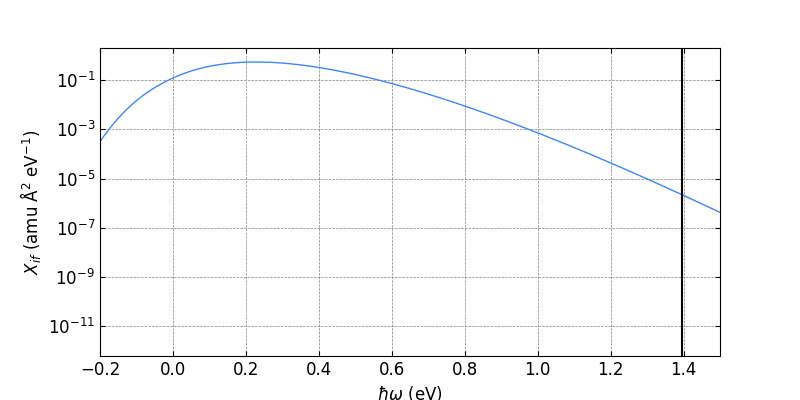

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))

ax.plot(energy_axis * 1e-3, ht_lineshape * 1e3,
        color=blue, linewidth=1, linestyle='-')

# ---------------------------------------------
# uncomment this to save/plot the 1D lineshape function F(\Delta) 
# np.savez("NVD_singlets_effmode_T78K",
#          x=energy_axis, 
#          y= 2 * np.pi / constants.hbar * M_if**2 * ht_lineshape * 1e3 * constants.eV
#         )
# ax.plot(energy_axis * 1e-3, 2 * np.pi / constants.hbar * M_if**2 * ht_lineshape * 1e3 * constants.eV ,
#         color=blue, linewidth=1, linestyle='-')
# ---------------------------------------------

ax.axvline(x=dE_ddh * 1e-3, ymin=0, ymax=1, color='k')

ax.set_xlim((-0.2, 1.5))

ax.grid(color='gray', linestyle='--', linewidth=0.5)

ax.tick_params(direction='in')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.set_xlabel(r'$\hbar\omega$ (eV)')
ax.set_ylabel(r'$X_{if}$ (amu Å$^2$ eV$^{-1}$)')
ax.set_yscale('log')

plt.show()

From the figure, the value of $X_{if}$ at $\Delta E$ can be identified.

In [8]:
index = np.where(energy_axis * 1e-3 - dE_ddh * 1e-3==0.0)[0]
Xif = ht_lineshape[index] * 1e3
print("%.4e"%Xif[0], "amu Å$^2$ eV$^{-1}$")

2.1752e-06 amu Å$^2$ eV$^{-1}$


The internal conversion rate can be then computed as

In [9]:
# degeneracy factor
g = 1

nv_ic_rate = 2 * np.pi / constants.hbar * g * M_if**2 * Xif * constants.eV * 1e-9 
print("%.4e"%nv_ic_rate[0], ' GHz')

1.1884e+00  GHz
